[    0.7 s] lag composites loaded from disk
[    0.7 s] drawing Fig04_lag_composites ... 

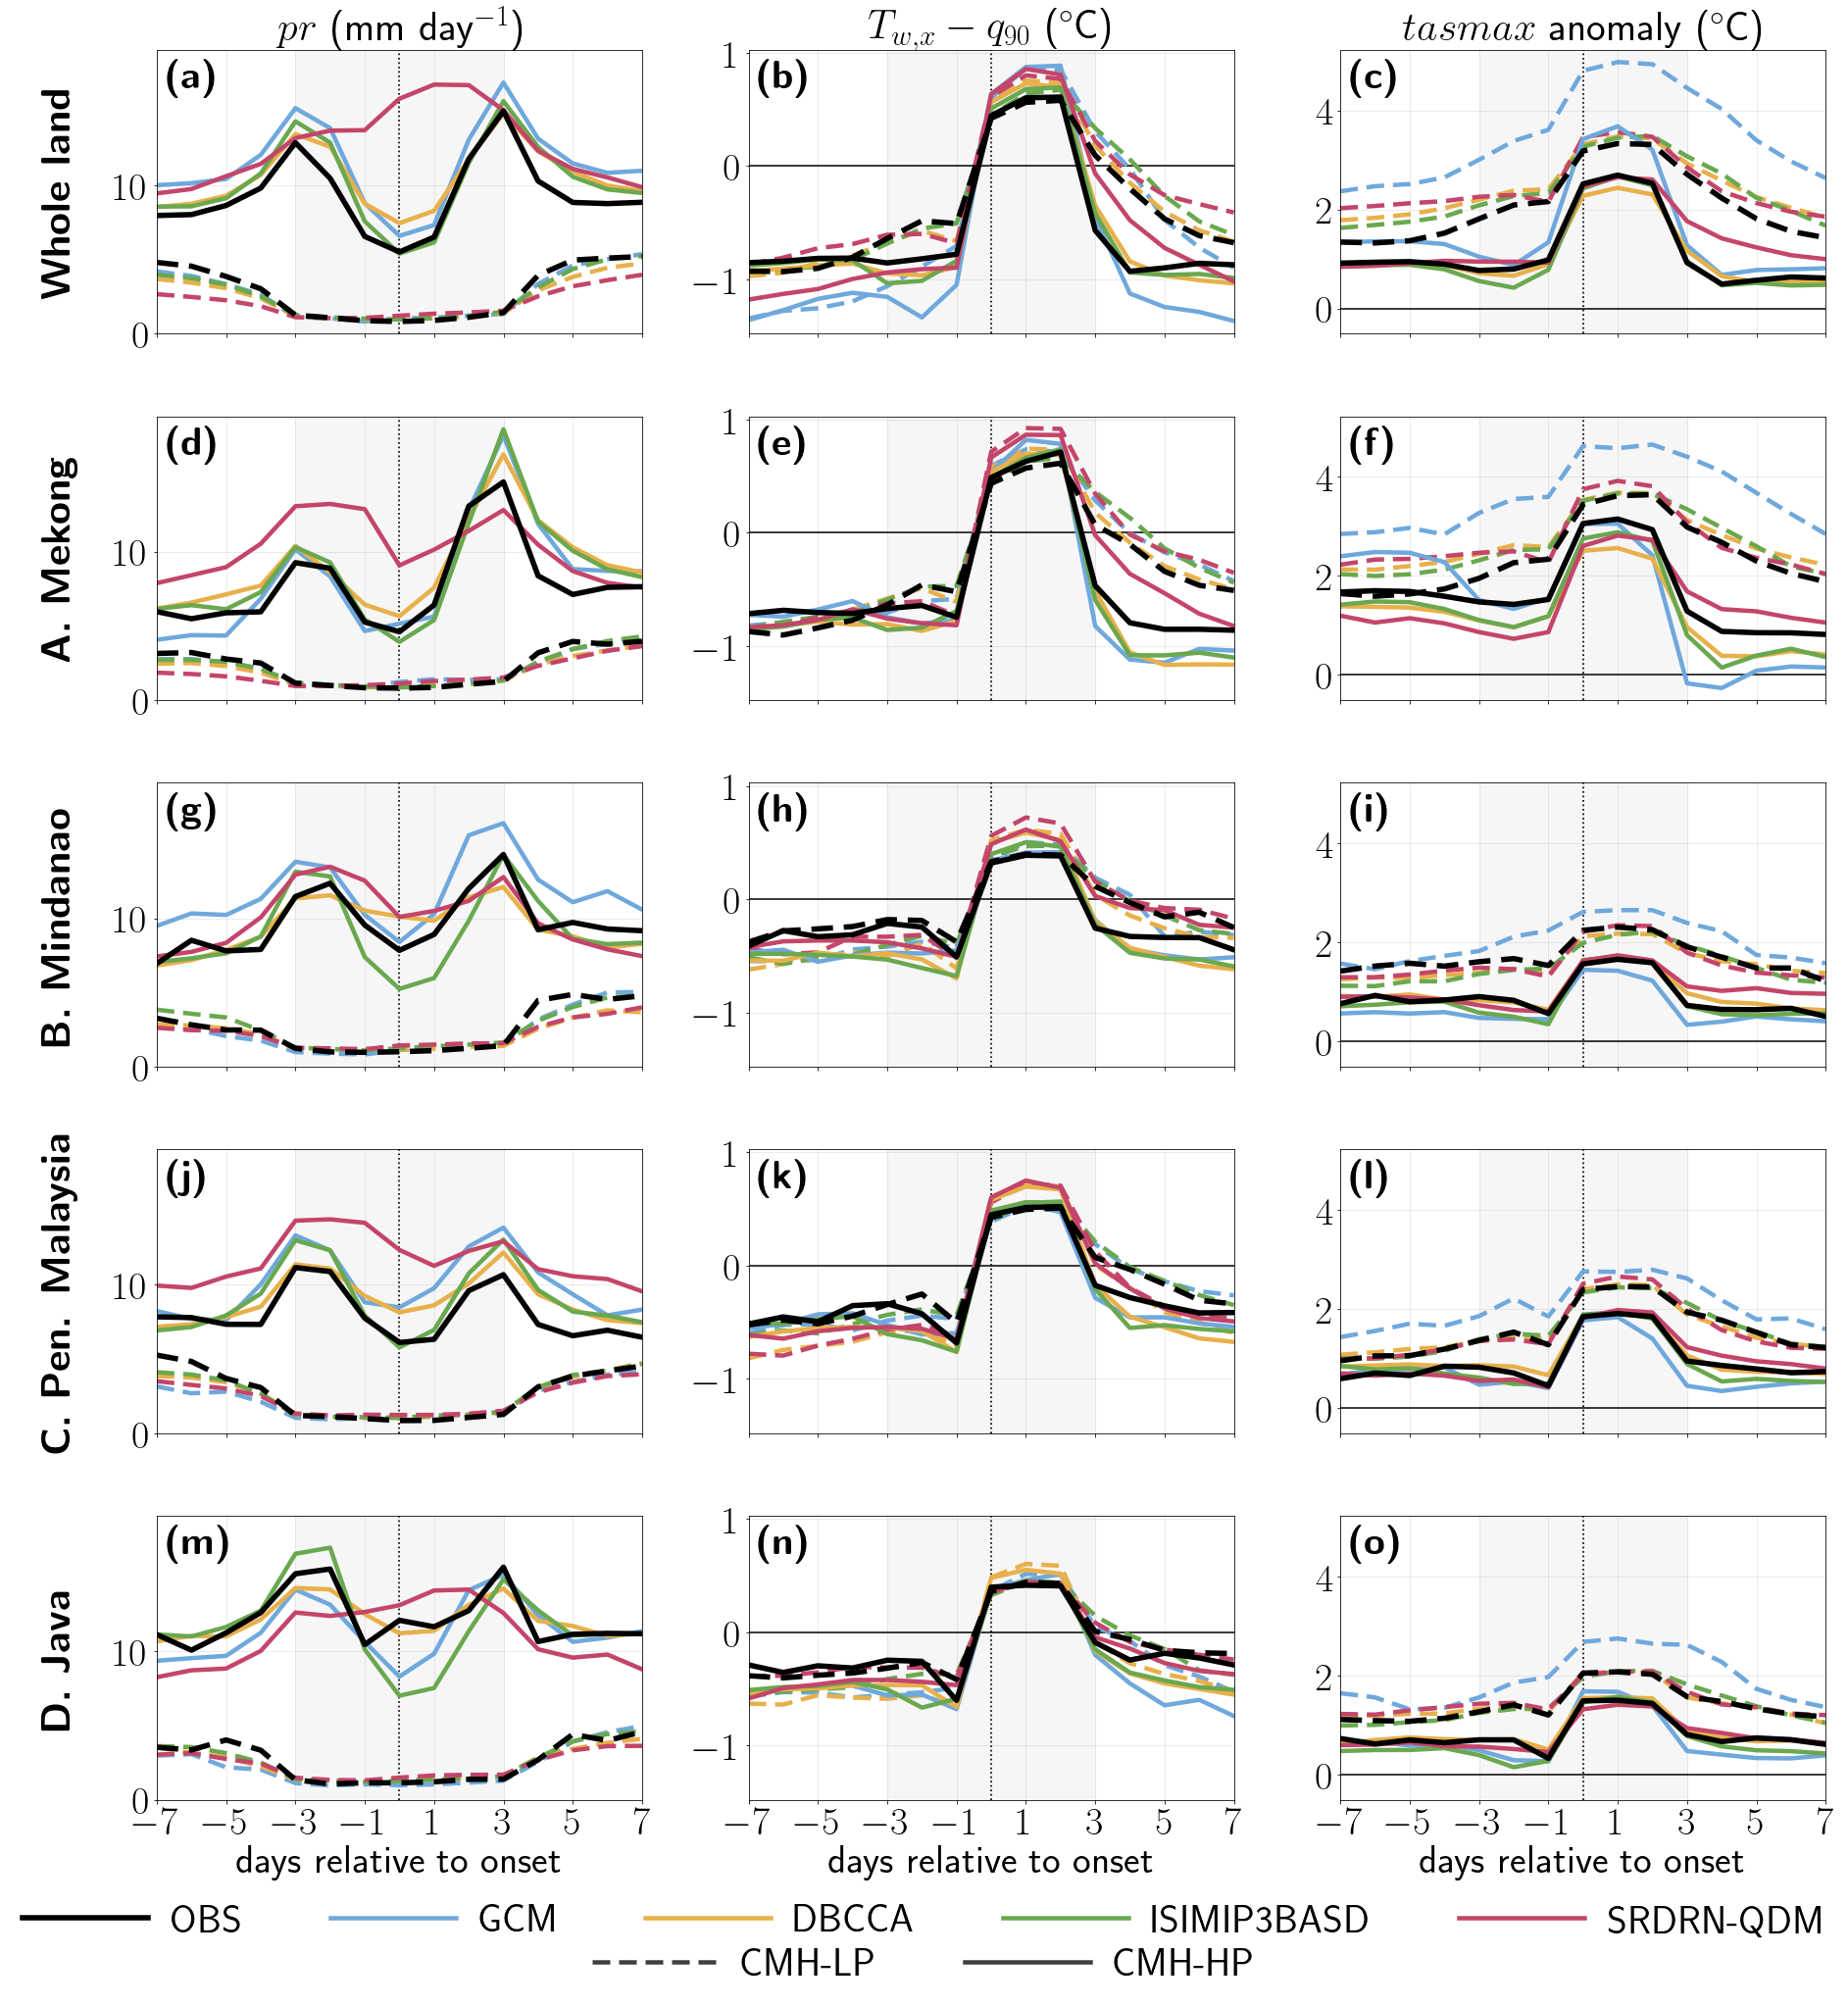

done in 4.1 s
[    4.8 s] TOTAL


In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, gc, time, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt, cartopy.io.shapereader as shpr
from concurrent.futures import ThreadPoolExecutor; from matplotlib.lines import Line2D
T0 = time.time(); tk = lambda s_: print(f'[{time.time()-T0:7.1f} s] {s_}', flush=True)
# ---------------- CONFIG ----------------
ROOT, SSP, HIST, VARS = r"D:/G_data", 'ssp126', ('1981', '2014'), ['tasmax', 'hurs', 'pr']
OBSF = {'tasmax': f"{ROOT}/obs-SEA/SEA-mswx-tasmax-1981-end2014.nc", 'hurs': f"{ROOT}/obs-SEA/SEA-mswx-rh-1981-end2014.nc", 'pr': f"{ROOT}/obs-SEA/SEA-mswep-pr-1981-end2014.nc"}
PATH = {'DBCCA': ROOT + "/out-DBCCA-overSEA/dbcca_{v}_combined_hist" + SSP + "_{m}.nc", 'ISIMIP3BASD': ROOT + "/out-BASD-ssp-orig/basd_{v}_combined_hist" + SSP + "_1981-2100_df4_{m}.nc",
        'SRDRN-QDM': ROOT + "/out-SRDRN-QDM-2100/srdrn_{v}_combined_hist" + SSP + "_{m}.nc", 'GCM': ROOT + "/CMIP6-histssp-input/hist" + SSP + "/{v}_combined_hist" + SSP + "_{m}.nc"}
PRODS, PORD = ['DBCCA', 'ISIMIP3BASD', 'SRDRN-QDM', 'GCM'], ['GCM', 'DBCCA', 'ISIMIP3BASD', 'SRDRN-QDM']   # compute order | plot order
MODS = ['ACCESS-CM2','ACCESS-ESM1-5','CMCC-CM2-SR5','CMCC-ESM2','CanESM5','EC-Earth3','EC-Earth3-Veg','FGOALS-g3','GFDL-ESM4','INM-CM5-0','IPSL-CM6A-LR','KACE-1-0-G','MIROC6','MPI-ESM1-2-HR','MRI-ESM2-0','NorESM2-MM','TaiESM1']
NM, PQ, MINLEN, RBIN, LANDRES = 5, 90, 3, [1., 5., 20.], '50m'                   # same event definition as Figure 1
BOXES = {'A Mekong': dict(lon=(100.5, 109.5), lat=(9.0, 18.0)), 'B Mindanao': dict(lon=(119.0, 126.0), lat=(5.0, 10.0)), 'C Pen. Malaysia': dict(lon=(98.5, 105.5), lat=(0.3, 8.8)), 'D Java': dict(lon=(105.0, 114.5), lat=(-10.0, -5.0))}
LAGS, LSET, ANCH, CLSL, VALL = np.arange(-7, 8), [3, 2, 5], ['onset', 'end'], {'light': 1, 'heavy': 3}, ['pr', 'twa', 'txa', 'rha']   # LSET[0] = rain-class window (onset +-3 d)
REGS = ['Whole land'] + list(BOXES); NJ, CH = min(8, os.cpu_count() or 4), 2000  # threads | cells per chunk
LAGF, USE_DISK, REDO_LAG = f"{ROOT}/out-compound-hist/lagcomp_{HIST[0]}-{HIST[1]}.npy", True, False   # USE_DISK: read old cache if it exists (read only)
PANCH, SAVE_FIG, FNAME, SAVE_DIR = ['onset'], False, 'Fig04_lag_composites', r"D:/G_data/paper-SRDRN/fig-ver3methods"   # PANCH += ['end'] for the SI version
FS, DLW, USETEX = 40, .5, True
# ---------------- LaTeX check ----------------
if USETEX:
    try: plt.rcParams['text.usetex'] = True; _f = plt.figure(); _f.text(.5, .5, r'$T_{w,x}$'); _f.canvas.draw(); plt.close(_f)
    except Exception: USETEX = False; plt.close('all')
# ---------------- I/O utils ----------------
def std_(ds):
    ren = {a: b for a, b in [('latitude', 'lat'), ('longitude', 'lon'), ('Latitude', 'lat'), ('Longitude', 'lon')] if a in ds.dims or a in ds.coords}; ds = ds.rename(ren) if ren else ds
    if ds.lat.size > 1 and float(ds.lat[0]) > float(ds.lat[-1]): ds = ds.sortby('lat')
    if float(ds.lon.min()) < 0: ds = ds.assign_coords(lon=(ds.lon % 360)).sortby('lon')
    return ds
def NL(d):
    cal = d.time.dt.calendar
    if cal in ('noleap', '365_day'): return d
    return d.convert_calendar('noleap', align_on='year', missing=np.nan) if cal == '360_day' else d.convert_calendar('noleap', align_on='date')
def fx(da, v):
    u = str(da.attrs.get('units', '')).lower().replace(' ', ''); s = da.isel(time=slice(0, 366))
    if v == 'tasmax' and (u in ('k', 'kelvin') or float(s.min()) > 100): da = da - 273.15
    elif v == 'pr' and (u in ('kgm-2s-1', 'kg/m2/s') or 0 < float(s.max()) < 0.01): da = da*86400.
    elif v == 'hurs' and float(s.max()) <= 1.5: da = da*100.
    return da
def landgrid(la, lo):
    import shapely.geometry as sgeom; from shapely.prepared import prep; from shapely.ops import unary_union
    pl = prep(unary_union(list(shpr.Reader(shpr.natural_earth(resolution=LANDRES, category='physical', name='land')).geometries()))); x = ((np.asarray(lo)+180.) % 360.) - 180.; X, Y = np.meshgrid(x, np.asarray(la))
    return np.fromiter((pl.contains(sgeom.Point(a, b)) for a, b in zip(X.ravel(), Y.ravel())), bool, X.size).reshape(X.shape)
LMK = globals().get('LMK', {})
def lm(la, lo):
    k = (la.size, lo.size, round(float(la[0]), 3), round(float(lo[0]), 3))
    if k not in LMK: LMK[k] = landgrid(la, lo)
    return LMK[k]
def stull(Tc, R):
    R = np.clip(R, 5., 99.5); return (Tc*np.arctan(0.151977*np.sqrt(R+8.313659)) + np.arctan(Tc+R) - np.arctan(R-1.676331) + 0.00391838*R**1.5*np.arctan(0.023101*R) - 4.686035).astype('f4')
def load3(fs):                                                                   # -> land-only (n, T) arrays of tasmax, hurs, pr on a common noleap time axis
    A = {}
    for v in VARS:
        d = std_(xr.open_dataset(fs[v], use_cftime=True))
        vn = v if v in d.data_vars else next((x for x in (['rh', 'relative_humidity'] if v == 'hurs' else []) if x in d.data_vars), next(x for x in d.data_vars if d[x].ndim == 3))
        A[v] = fx(NL(d[vn].sel(time=slice(*HIST))).astype('float32').transpose('time', 'lat', 'lon').load(), v); d.close()
    ky = {v: pd.MultiIndex.from_arrays([A[v].time.dt.year.values, A[v].time.dt.dayofyear.values]) for v in VARS}; com = ky['tasmax'].intersection(ky['hurs']).intersection(ky['pr'])
    for v in VARS: A[v] = A[v].isel(time=np.flatnonzero(ky[v].isin(com)))
    la, lo = A['tasmax'].lat.values.astype('f8'), A['tasmax'].lon.values.astype('f8')
    for v in ('hurs', 'pr'):
        if not (A[v].lat.size == la.size and A[v].lon.size == lo.size and np.allclose(A[v].lat, la, atol=1e-3) and np.allclose(A[v].lon, lo, atol=1e-3)): A[v] = A[v].reindex(lat=la, lon=lo, method='nearest')
    land = lm(la, lo); fin = np.ones(land.shape, bool)
    for v in VARS: fin &= np.isfinite(A[v].values).mean(0) >= .9
    VI = np.flatnonzero((land & fin).ravel()); nt = A['tasmax'].sizes['time']; X = {v: np.ascontiguousarray(A[v].values.reshape(nt, -1)[:, VI].T) for v in VARS}
    MO = A['tasmax'].time.dt.month.values.astype('i4'); del A; gc.collect()
    return X, la[VI // lo.size], lo[VI % lo.size], MO
# ---------------- event detection + lag sums on one chunk of cells (independent -> parallel) ----------------
def detect(TW, M0):
    n, T = TW.shape; r_ = np.arange(n)
    MTW = np.stack([np.nanmean(TW[:, M0 == m], 1) for m in range(12)], 1); cs_ = np.concatenate([MTW, MTW[:, :NM-1]], 1); ons = np.nanargmax(np.stack([cs_[:, i:i+NM].mean(1) for i in range(12)], 1), 1)
    INS = np.zeros((n, 12), bool); INS[r_[:, None], (ons[:, None] + np.arange(NM)) % 12] = True; SD = INS[:, M0]
    V = SD & np.isfinite(TW); kq = V.sum(1); A = np.sort(np.where(V, TW, np.inf), 1); del V               # in-season q90 (= np.nanpercentile 'linear')
    pos = (np.maximum(kq, 1) - 1)*PQ/100.; lo = np.floor(pos).astype(int); hi = np.minimum(lo + 1, np.maximum(kq - 1, 0))
    with np.errstate(invalid='ignore'): q = (A[r_, lo] + (A[r_, hi] - A[r_, lo])*(pos - lo)).astype('f4')
    q[kq == 0] = np.nan; del A
    dd = np.diff(np.pad(((TW > q[:, None]) & SD).astype(np.int8), ((0, 0), (1, 1))), axis=1); c, s = np.nonzero(dd == 1); _, e = np.nonzero(dd == -1); del dd
    du = e - s; k = du >= MINLEN; return q, SD, c[k], s[k], du[k]
def lagchunk(tx, rh, PR, M0, la, lo):                                            # -> sums, counts [window, anchor, region, var, class, lag], events [window, region, class]
    TW = stull(tx, rh); T = TW.shape[1]; q, SD, c, s, du = detect(TW, M0)
    with np.errstate(invalid='ignore'): sm = lambda A: np.nanmean(np.where(SD, A, np.nan), 1)
    V = [(PR, None), (TW, q), (tx, sm(tx)), (rh, sm(rh))]; del SD
    RC = [np.ones(la.size, bool)] + [(lo >= bb['lon'][0]) & (lo <= bb['lon'][1]) & (la >= bb['lat'][0]) & (la <= bb['lat'][1]) for bb in BOXES.values()]
    S = np.zeros((len(LSET), len(ANCH), len(REGS), len(V), len(CLSL), LAGS.size)); C = np.zeros_like(S); cnt = np.zeros((len(LSET), len(REGS), len(CLSL)), 'i8')
    for iw, Lw in enumerate(LSET):
        mx = np.full(c.size, -1., 'f4')
        for kk in range(-Lw, Lw + 1): t = s + kk; ok = (t >= 0) & (t < T); mx[ok] = np.fmax(mx[ok], PR[c[ok], t[ok]])
        cls = np.digitize(mx, RBIN).astype('i1'); cls[mx < 0] = -1
        for j, cv in enumerate(CLSL.values()):
            m = cls == cv; cc, ss, ee = c[m], s[m], (s + du - 1)[m]; RE = [rc[cc] for rc in RC]; cnt[iw, :, j] = [x.sum() for x in RE]
            for ia, a0 in enumerate((ss, ee)):                                   # anchor: onset day | last event day
                for il, lg in enumerate(LAGS):
                    t = a0 + lg; ok = (t >= 0) & (t < T); tc = np.clip(t, 0, T - 1)
                    for iv, (A, ref) in enumerate(V):
                        z = A[cc, tc] - (ref[cc] if ref is not None else 0.); f = ok & np.isfinite(z)
                        for ir, rr in enumerate(RE): w = f & rr; S[iw, ia, ir, iv, j, il] = z[w].sum(dtype='f8'); C[iw, ia, ir, iv, j, il] = w.sum()
    return S, C, cnt
def runlag(fs):
    X, LA_, LO_, MO = load3(fs); M0 = MO - 1; n = X['tasmax'].shape[0]
    job = lambda ab: lagchunk(X['tasmax'][ab[0]:ab[1]], X['hurs'][ab[0]:ab[1]], X['pr'][ab[0]:ab[1]], M0, LA_[ab[0]:ab[1]], LO_[ab[0]:ab[1]])
    with ThreadPoolExecutor(NJ) as ex: R = list(ex.map(job, [(i, min(i + CH, n)) for i in range(0, n, CH)]))
    S, C, cnt = sum(r[0] for r in R), sum(r[1] for r in R), sum(r[2] for r in R); del X, R; gc.collect()
    with np.errstate(invalid='ignore', divide='ignore'): return dict(lag=(S/np.where(C > 0, C, np.nan)).astype('f4'), cnt=cnt)
# ---------------- COMPUTE: RAM -> (old disk cache, read only) -> only missing entries ----------------
CFG = (tuple(LAGS.tolist()), tuple(LSET), tuple(REGS), HIST); LAGH = {} if REDO_LAG else globals().get('LAGH', {}); ERR = {}
if LAGH.get('cfg') == CFG: tk('lag composites found in RAM')
elif USE_DISK and not REDO_LAG and os.path.exists(LAGF):
    _d = np.load(LAGF, allow_pickle=True).item(); LAGH = _d if _d.get('cfg') == CFG else {}; tk('lag composites loaded from disk' if LAGH else 'disk cache has another config -> recompute')
if LAGH.get('cfg') != CFG: LAGH = {'cfg': CFG}
JOBS = [('OBS', [('obs', OBSF)])] + [(p, [(m, {v: PATH[p].format(v=v, m=m) for v in VARS}) for m in MODS]) for p in PRODS]
for p, lst in JOBS:
    todo = [(m, fs) for m, fs in lst if (p, m) not in LAGH and all(os.path.exists(f) for f in fs.values())]
    if not todo: continue
    t_ = time.time(); print(f'[{t_-T0:7.1f} s] running {p} ...', end=' ', flush=True)
    for m, fs in todo:
        try: LAGH[(p, m)] = runlag(fs)
        except Exception as e: ERR[(p, m)] = f'{type(e).__name__}: {e}'
        gc.collect()
    print(f'done in {time.time()-t_:.1f} s', flush=True)
OKL = {p: [m for m in MODS if (p, m) in LAGH] for p in PRODS}; SRC = ['OBS'] + [p for p in PORD if OKL.get(p)]
MED = {p: (LAGH[('OBS', 'obs')]['lag'] if p == 'OBS' else np.nanmedian(np.stack([LAGH[(p, m)]['lag'] for m in OKL[p]]), 0)) for p in SRC}   # [window, anchor, region, var, class, lag]
# ---------------- FIG 4 (CMH-LP / CMH-HP, +0.5 lw) ----------------
t_ = time.time(); print(f'[{t_-T0:7.1f} s] drawing {FNAME} ...', end=' ', flush=True)
plt.rcParams.update({'text.usetex': USETEX, 'font.size': FS, 'axes.titlesize': FS+2, 'axes.labelsize': FS, 'xtick.labelsize': FS, 'ytick.labelsize': FS, 'legend.fontsize': FS})
bf = (lambda s_: r'\textbf{' + s_ + '}') if USETEX else (lambda s_: s_); LET = 'abcdefghijklmnopqrstuvwxyz'
RLAB = {r: (r if r == 'Whole land' else r.split()[0] + '. ' + ' '.join(r.split()[1:])) for r in REGS}
CLAB, LSTY = {'light': 'CMH-LP', 'heavy': 'CMH-HP'}, {'light': (0, (4, 2)), 'heavy': '-'}
PCOL = {'GCM': '#6FA8DC', 'DBCCA': '#E8B04B', 'ISIMIP3BASD': '#6AA84F', 'SRDRN-QDM': '#C4456A'}
VN = ['pr', 'twa', 'txa']; VYL = {'pr': r'$pr$ (mm day$^{-1}$)', 'twa': r'$T_{w,x} - q_{90}$ ($^{\circ}$C)', 'txa': r'$tasmax$ anomaly ($^{\circ}$C)'}
for ia, an in enumerate(ANCH):
    if an not in PANCH: continue
    fig, AX = plt.subplots(len(REGS), len(VN), figsize=(27, 6.2*len(REGS)), sharex=True)
    for ir, r in enumerate(REGS):
        for ic, v in enumerate(VN):
            ax = AX[ir, ic]; iv = VALL.index(v); ax.axvline(0, color='k', lw=1.2 + DLW, ls=':')
            if an == 'onset': ax.axvspan(-LSET[0], LSET[0], color='0.965', zorder=0)
            if v != 'pr': ax.axhline(0, color='k', lw=1 + DLW)
            for j, cn in enumerate(CLSL):
                for p in SRC[1:]: ax.plot(LAGS, MED[p][0, ia, ir, iv, j], color=PCOL[p], lw=4 + DLW, ls=LSTY[cn])
                ax.plot(LAGS, MED['OBS'][0, ia, ir, iv, j], color='k', lw=5 + DLW, ls=LSTY[cn], zorder=6)
            ax.set_xlim(LAGS[0], LAGS[-1]); ax.set_xticks(LAGS[::2]); ax.grid(alpha=.3); ax.text(.02, .97, bf(f'({LET[ir*len(VN) + ic]})'), transform=ax.transAxes, va='top', fontsize=FS)
            if ir == 0: ax.set_title(VYL[v])
            if ir == len(REGS) - 1: ax.set_xlabel('days relative to onset' if an == 'onset' else 'days relative to the last event day')
            if ic == 0: ax.text(-.2, .5, bf(RLAB[r]), transform=ax.transAxes, rotation=90, va='center', ha='center', fontsize=FS+2)
    for ic, v in enumerate(VN):                                                  # same y-range down each column; pr starts at 0
        lo_, hi_ = min(AX[ir, ic].get_ylim()[0] for ir in range(len(REGS))), max(AX[ir, ic].get_ylim()[1] for ir in range(len(REGS)))
        for ir in range(len(REGS)): AX[ir, ic].set_ylim(0 if v == 'pr' else lo_, hi_)
    fig.tight_layout(rect=(.02, .085, 1, .98)); LK = dict(loc='lower center', frameon=False, handlelength=3.2, handletextpad=.6, columnspacing=2.2, borderaxespad=0.)
    H1 = [Line2D([], [], color='k', lw=5 + DLW, label='OBS')] + [Line2D([], [], color=PCOL[p], lw=4 + DLW, label=p) for p in SRC[1:]]
    H2 = [Line2D([], [], color='0.25', lw=4 + DLW, ls=LSTY[c_], label=CLAB[c_]) for c_ in CLSL]
    fig.legend(handles=H1, ncol=len(H1), bbox_to_anchor=(.5, .07), **LK); fig.legend(handles=H2, ncol=len(H2), bbox_to_anchor=(.5, .05), **LK)
    if SAVE_FIG: os.makedirs(SAVE_DIR, exist_ok=True); fig.savefig(os.path.join(SAVE_DIR, FNAME + ('' if an == 'onset' else '_end') + '.pdf'), dpi=300, bbox_inches='tight')
    plt.show(); plt.close(fig)
print(f'done in {time.time()-t_:.1f} s', flush=True); tk('TOTAL')